## 1. Import and Config

In [10]:
import json
import random          # [VĐ3] cần cho việc cố định seed
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import segmentation_models_pytorch as smp
import ssl
ssl._create_default_https_context = ssl._create_unverified_context  # [Lần 5] cho phép tải trọng số pretrained qua SSL trên Windows

# [VĐ3] Cố định seed — phải chạy TRƯỚC mọi thao tác ngẫu nhiên
# (khởi tạo model ở cell 7, shuffle/augment ở cell 5). Mục đích: mỗi run
# xuất phát giống nhau → so sánh run-to-run mới tách được "cải thiện thật".
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
THRESHOLD = 0.5          
IMG_SIZE = 352
BATCH_SIZE = 8
LEARNING_RATE = 0.0001
EPOCHS = 60
PATIENCE = 10           # Dừng sớm nếu val không cải thiện

DEVICE = "cuda"
DATA = Path("..") / "data"
SPLIT_PATH = DATA / "splits" / "unet_split.json"
SAVE_DIR = Path("..") / "checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = SAVE_DIR / "unet_best.pth"

## 2. Dataset

In [11]:
class PolypDataset(Dataset):
    """Dataset cho bài toán polyp segmentation.
    Đọc ảnh + mask từ unet_split.json, resize và augmentation.
    """

    def __init__(self, entries, data_dir, img_size=256, augment=False):
        """
        Args:
            entries: danh sách dict từ unet_split.json (mỗi dict có image, mask, label)
            data_dir: thư mục gốc chứa data
            img_size: kích thước resize (vuông)
            augment: có áp dụng augmentation không (chỉ dùng cho train)
        """
        self.entries = entries
        self.data_dir = Path(data_dir)
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        entry = self.entries[idx]

        # Đọc ảnh và mask
        image = Image.open(self.data_dir / entry["image"]).convert("RGB")
        mask = Image.open(self.data_dir / entry["mask"]).convert("L")  # Grayscale

        # Resize về cùng kích thước
        image = image.resize((self.img_size, self.img_size), Image.BILINEAR)
        mask = mask.resize((self.img_size, self.img_size), Image.NEAREST)

        # Chuyển sang numpy
        image = np.array(image, dtype=np.float32) / 255.0  # Chuẩn hóa [0, 1]
        mask = np.array(mask, dtype=np.float32) / 255.0
        mask = (mask > 0.5).astype(np.float32)  # Nhị phân hóa mask

        # Augmentation (chỉ áp dụng cho tập train)
        if self.augment:
            # Lật ngang ngẫu nhiên
            if np.random.rand() > 0.5:
                image = np.flip(image, axis=1).copy()
                mask = np.flip(mask, axis=1).copy()
            # Lật dọc ngẫu nhiên
            if np.random.rand() > 0.5:
                image = np.flip(image, axis=0).copy()
                mask = np.flip(mask, axis=0).copy()
            # Xoay 90/180/270 độ ngẫu nhiên
            k = np.random.randint(0, 4)
            image = np.rot90(image, k, axes=(0, 1)).copy()
            mask = np.rot90(mask, k, axes=(0, 1)).copy()
            # Điều chỉnh độ sáng ngẫu nhiên (chỉ ảnh, không áp dụng cho mask)
            brightness = np.random.uniform(0.8, 1.2)
            image = np.clip(image * brightness, 0, 1).astype(np.float32)


        # [Lần 5] Chuẩn hóa ImageNet — BẮT BUỘC cho encoder pretrained.
        # Encoder ResNet học trên ảnh chuẩn hóa mean/std ImageNet; thiếu bước này
        # input lệch phân phối → mất gần hết lợi ích pretrained.
        # Đặt SAU brightness jitter (jitter làm trong thang [0,1]) — đảo thứ tự là sai.
        IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        
        # Chuyển sang tensor: (H, W, C) → (C, H, W)
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)  # (1, H, W)

        return image, mask

## 3. DataLoader

In [12]:
# Đọc file split
with open(SPLIT_PATH, "r") as f:
    splits = json.load(f)

print(f"Train: {len(splits['train'])} | Val: {len(splits['val'])} | Test: {len(splits['test'])}")

# Tạo dataset
train_dataset = PolypDataset(splits["train"], DATA, IMG_SIZE, augment=True)
val_dataset = PolypDataset(splits["val"], DATA, IMG_SIZE, augment=False)
test_dataset = PolypDataset(splits["test"], DATA, IMG_SIZE, augment=False)

# [VĐ3] Cố định thứ tự shuffle của train_loader, độc lập với RNG toàn cục
g = torch.Generator()
g.manual_seed(SEED)

# [VĐ1] num_workers=0: Windows + Jupyter spawn worker bị treo (đã kiểm chứng).
# Augmentation chạy trên process chính (đã seed ở cell 1) → vẫn tái lập được.
# pin_memory giữ lại để đi kèm non_blocking=True bên training loop (lợi ích biên).
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=True, generator=g,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)

# Kiểm tra nhanh 1 batch
images, masks = next(iter(train_loader))
print(f"Batch ảnh : {images.shape}")   # (B, 3, 256, 256)
print(f"Batch mask: {masks.shape}")    # (B, 1, 256, 256)
print(f"Giá trị mask: min={masks.min()}, max={masks.max()}")

Train: 1520 | Val: 190 | Test: 190
Batch ảnh : torch.Size([8, 3, 352, 352])
Batch mask: torch.Size([8, 1, 352, 352])
Giá trị mask: min=0.0, max=1.0


## 4. Kiến trúc U-Net

In [13]:


# [Lần 5] U-Net với encoder ResNet34 pretrained ImageNet.
# Thay cho vanilla U-Net tay (DoubleConv + UNet đã xóa).
# Lý do: lỗi còn lại sau 4 run là phân biệt texture polyp ↔ nếp gấp môn vị;
# encoder pretrained cấp prior texture để xử lý đúng lớp lỗi này.
# Output vẫn là logits (B,1,H,W) → loss/metric/mọi cell sau KHÔNG cần đổi.
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",   # train: khởi tạo bằng trọng số ImageNet rồi fine-tune toàn bộ
    in_channels=3,
    classes=1,
).to(DEVICE)

# Đếm số lượng parameters
total_params = sum(p.numel() for p in model.parameters())
print(f"Tổng parameters: {total_params:,}")
print(f"Kích thước model: ~{total_params * 4 / 1024**2:.1f} MB")

Tổng parameters: 24,436,369
Kích thước model: ~93.2 MB


## 5. Loss and metrics

In [14]:
def dice_coefficient(pred, target, threshold=THRESHOLD, smooth=1e-6):
    """Tính Dice coefficient. Dice(∅, ∅) = 1.0 (quy ước y tế)."""
    pred_bin = (torch.sigmoid(pred) > threshold).float()
    dice_scores = []
    for i in range(pred_bin.shape[0]):
        p = pred_bin[i].view(-1)
        t = target[i].view(-1)
        if p.sum() == 0 and t.sum() == 0:
            dice_scores.append(1.0)
            continue
        intersection = (p * t).sum()
        dice = (2.0 * intersection + smooth) / (p.sum() + t.sum() + smooth)
        dice_scores.append(dice.item())
    return np.mean(dice_scores)


def iou_score(pred, target, threshold=THRESHOLD, smooth=1e-6):
    """Tính IoU. IoU(∅, ∅) = 1.0 (cùng quy ước với Dice)."""
    pred_bin = (torch.sigmoid(pred) > threshold).float()
    iou_scores = []
    for i in range(pred_bin.shape[0]):
        p = pred_bin[i].view(-1)
        t = target[i].view(-1)
        if p.sum() == 0 and t.sum() == 0:
            iou_scores.append(1.0)
            continue
        intersection = (p * t).sum()
        union = p.sum() + t.sum() - intersection
        iou = (intersection + smooth) / (union + smooth)
        iou_scores.append(iou.item())
    return np.mean(iou_scores)


class BCEDiceLoss(nn.Module):
    """BCE + Dice Loss. [VĐ4] Dice tính TỪNG ẢNH rồi trung bình (macro),
    khớp với metric dice_coefficient — thay vì gộp cả batch như trước.
    Lý do: bản gộp batch để ảnh polyp lớn chi phối gradient, polyp nhỏ bị
    pha loãng; bản per-image phạt đều mọi ảnh → ép model quan tâm cả polyp nhỏ.
    """
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred, target):
        bce_loss = self.bce(pred, target)

        pred_sig = torch.sigmoid(pred)
        smooth = 1e-6
        B = pred.shape[0]
        p = pred_sig.view(B, -1)          # [VĐ4] tách theo từng ảnh
        t = target.view(B, -1)
        inter = (p * t).sum(dim=1)
        dice = (2.0 * inter + smooth) / (p.sum(dim=1) + t.sum(dim=1) + smooth)
        dice_loss = 1 - dice.mean()       # trung bình trên batch

        return bce_loss + dice_loss


criterion = BCEDiceLoss()
# [VĐ2] AdamW + weight_decay: regularization rẻ, siết overfitting nhẹ
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
# Bỏ verbose=True (đã deprecated); ta tự in LR trong cell 11 để thấy khi nào scheduler giảm
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=5, factor=0.5
)

## 6. Training Loop

In [15]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    """Chạy 1 epoch training. [VĐ1] Dùng AMP (mixed precision)."""
    model.train()
    total_loss = 0
    total_dice = 0

    for images, masks in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):          # [VĐ1] tính fp16: nhanh hơn + nhẹ VRAM
            outputs = model(images)
            loss = criterion(outputs, masks)
        scaler.scale(loss).backward()             # scale loss tránh underflow gradient fp16
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        total_dice += dice_coefficient(outputs, masks)

    return total_loss / len(loader), total_dice / len(loader)


@torch.no_grad()
def validate(model, loader, criterion, device):
    """Đánh giá trên tập validation. [VĐ1] Cũng bọc autocast cho nhẹ VRAM."""
    model.eval()
    total_loss = 0
    total_dice = 0

    for images, masks in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, masks)
        total_loss += loss.item()
        total_dice += dice_coefficient(outputs, masks)

    return total_loss / len(loader), total_dice / len(loader)


# === BẮT ĐẦU TRAINING ===
scaler = torch.amp.GradScaler("cuda")   # [VĐ1] quản lý scale gradient cho AMP — tạo 1 lần

history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": []
}

best_val_dice = 0.0
patience_counter = 0

print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Val Loss':>10} | {'Train Dice':>10} | {'Val Dice':>10} | {'LR':>8} | {'Status'}")
print("-" * 90)

for epoch in range(1, EPOCHS + 1):
    train_loss, train_dice = train_one_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE)
    val_loss, val_dice = validate(model, val_loader, criterion, DEVICE)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_dice)
    current_lr = optimizer.param_groups[0]['lr']   # [VĐ3] để thấy scheduler giảm LR lúc nào

    status = ""
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        status = "✓ Saved"
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\nDừng sớm tại epoch {epoch} — Val Dice không cải thiện sau {PATIENCE} epoch.")
            break

    print(f"{epoch:>5} | {train_loss:>10.4f} | {val_loss:>10.4f} | {train_dice:>10.4f} | {val_dice:>10.4f} | {current_lr:>8.1e} | {status}")

print(f"\nBest Val Dice: {best_val_dice:.4f}")
print(f"Model đã lưu tại: {BEST_MODEL_PATH}")

# Lưu history (loss/dice theo epoch) ra file — để vẽ lại biểu đồ mà không cần train lại
with open(SAVE_DIR / "history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=2)
print("Đã lưu history tại:", SAVE_DIR / "history.json")

Epoch | Train Loss |   Val Loss | Train Dice |   Val Dice |       LR | Status
------------------------------------------------------------------------------------------
    1 |     1.2267 |     1.0117 |     0.3716 |     0.4652 |  1.0e-04 | ✓ Saved
    2 |     0.9403 |     0.7955 |     0.6765 |     0.5878 |  1.0e-04 | ✓ Saved
    3 |     0.7829 |     0.7447 |     0.8225 |     0.9176 |  1.0e-04 | ✓ Saved
    4 |     0.7204 |     0.6955 |     0.8361 |     0.9105 |  1.0e-04 | 
    5 |     0.6742 |     0.6462 |     0.8550 |     0.9346 |  1.0e-04 | ✓ Saved
    6 |     0.6518 |     0.6469 |     0.8801 |     0.9334 |  1.0e-04 | 
    7 |     0.6413 |     0.6367 |     0.8584 |     0.9143 |  1.0e-04 | 
    8 |     0.6212 |     0.6263 |     0.8953 |     0.9376 |  1.0e-04 | ✓ Saved
    9 |     0.6264 |     0.6411 |     0.8804 |     0.9156 |  1.0e-04 | 
   10 |     0.6089 |     0.6473 |     0.9022 |     0.9079 |  1.0e-04 | 
   11 |     0.6067 |     0.6135 |     0.8962 |     0.9398 |  1.0e-04 | ✓ Sav

## 7. Visualize train and valid

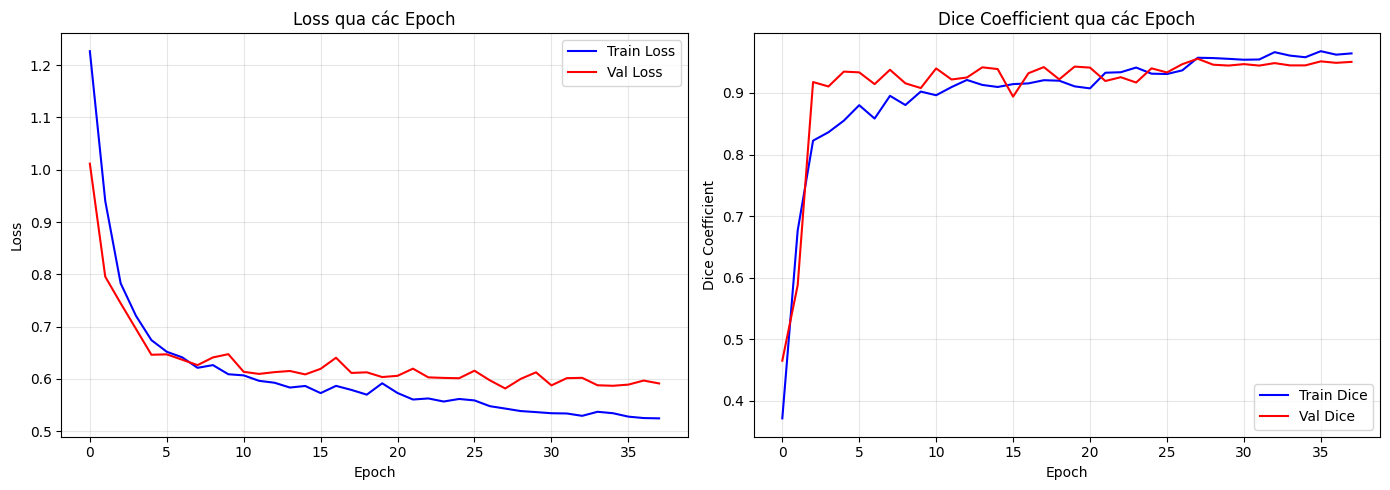

Đã lưu biểu đồ tại: ..\checkpoints\training_curves.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Biểu đồ Loss ---
axes[0].plot(history["train_loss"], label="Train Loss", color="blue")
axes[0].plot(history["val_loss"], label="Val Loss", color="red")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss qua các Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Biểu đồ Dice ---
axes[1].plot(history["train_dice"], label="Train Dice", color="blue")
axes[1].plot(history["val_dice"], label="Val Dice", color="red")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice Coefficient")
axes[1].set_title("Dice Coefficient qua các Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(SAVE_DIR / "training_curves.png", dpi=150)
plt.show()

print("Đã lưu biểu đồ tại:", SAVE_DIR / "training_curves.png")

## 8. Đánh giá tập test

In [17]:
# ============================================================
# ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST
# Tách 2 nhóm: ảnh có polyp (đo khoanh vùng tốt tới đâu) và
# ảnh bình thường (đo model có vẽ nhầm polyp không).
# ============================================================

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()

all_dice, all_iou = [], []
polyp_dice, polyp_iou = [], []
normal_dice, normal_iou = [], []

# Đếm pixel để tính Precision/Recall (nhóm polyp) và Specificity (nhóm normal)
polyp_TP = polyp_FP = polyp_FN = 0
normal_TN = normal_FP = 0

test_labels = [e["label"] for e in splits["test"]]
sample_idx = 0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        outputs = model(images)

        for i in range(images.shape[0]):
            pred_single = outputs[i:i+1]
            mask_single = masks[i:i+1]

            d = dice_coefficient(pred_single, mask_single)
            iou = iou_score(pred_single, mask_single)
            all_dice.append(d)
            all_iou.append(iou)

            pred_bin = (torch.sigmoid(pred_single) > THRESHOLD).float().view(-1)
            target = mask_single.view(-1)

            if sample_idx < len(test_labels):
                if test_labels[sample_idx] == "polyp":
                    polyp_dice.append(d)
                    polyp_iou.append(iou)
                    polyp_TP += ((pred_bin == 1) & (target == 1)).sum().item()
                    polyp_FP += ((pred_bin == 1) & (target == 0)).sum().item()
                    polyp_FN += ((pred_bin == 0) & (target == 1)).sum().item()
                elif test_labels[sample_idx] == "normal":
                    normal_dice.append(d)
                    normal_iou.append(iou)
                    normal_TN += ((pred_bin == 0) & (target == 0)).sum().item()
                    normal_FP += ((pred_bin == 1) & (target == 0)).sum().item()

            sample_idx += 1

eps = 1e-6
precision = polyp_TP / (polyp_TP + polyp_FP + eps)
recall = polyp_TP / (polyp_TP + polyp_FN + eps)
specificity = normal_TN / (normal_TN + normal_FP + eps)
clean = sum(1 for d in normal_dice if d > 0.5)

# ============================================================
# IN KẾT QUẢ
# ============================================================
print("=" * 55)
print("KẾT QUẢ TRÊN TẬP TEST")
print("=" * 55)

print(f"\n--- Toàn bộ test set ({len(all_dice)} ảnh) ---")
print(f"  Dice : {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
print(f"  IoU  : {np.mean(all_iou):.4f} ± {np.std(all_iou):.4f}")

print(f"\n--- Ảnh có polyp ({len(polyp_dice)} ảnh): model khoanh vùng polyp tốt tới đâu ---")
print(f"  Dice      : {np.mean(polyp_dice):.4f} ± {np.std(polyp_dice):.4f}")
print(f"  IoU       : {np.mean(polyp_iou):.4f} ± {np.std(polyp_iou):.4f}")
print(f"  Precision : {precision:.4f}   (model đoán là polyp thì đúng bao nhiêu %, cao = ít báo nhầm)")
print(f"  Recall    : {recall:.4f}   (polyp thật model bắt được bao nhiêu %, cao = ít bỏ sót)")

print(f"\n--- Ảnh bình thường ({len(normal_dice)} ảnh): model có vẽ nhầm polyp không ---")
print(f"  Specificity : {specificity:.4f}   (nhận đúng vùng mô lành bao nhiêu %, cao = ít vẽ nhầm)")
print(f"  Số ảnh không bị vẽ nhầm: {clean}/{len(normal_dice)} = {clean/len(normal_dice)*100:.1f}%")

# Lưu kết quả test ra file — để dán vào báo cáo/log mà không cần chạy lại
test_results = {
    "overall": {"dice": float(np.mean(all_dice)), "dice_std": float(np.std(all_dice)),
                "iou": float(np.mean(all_iou)), "iou_std": float(np.std(all_iou))},
    "polyp": {"dice": float(np.mean(polyp_dice)), "dice_std": float(np.std(polyp_dice)),
              "iou": float(np.mean(polyp_iou)), "iou_std": float(np.std(polyp_iou)),
              "precision": float(precision), "recall": float(recall)},
    "normal": {"specificity": float(specificity),
               "clean_images": int(clean), "total_images": int(len(normal_dice)),
               "clean_rate": float(clean / len(normal_dice))},
    "config": {"img_size": IMG_SIZE, "threshold": THRESHOLD,
               "encoder": "resnet34", "seed": SEED},
}
with open(SAVE_DIR / "test_results.json", "w", encoding="utf-8") as f:
    json.dump(test_results, f, ensure_ascii=False, indent=2)
print("\nĐã lưu kết quả test tại:", SAVE_DIR / "test_results.json")

C:\Users\USER\AppData\Local\Temp\ipykernel_4224\2463481883.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location

KẾT QUẢ TRÊN TẬP TEST

--- Toàn bộ test set (190 ảnh) ---
  Dice : 0.9406 ± 0.1502
  IoU  : 0.9123 ± 0.1755

--- Ảnh có polyp (100 ảnh): model khoanh vùng polyp tốt tới đâu ---
  Dice      : 0.8971 ± 0.1703
  IoU       : 0.8433 ± 0.1965
  Precision : 0.8949   (model đoán là polyp thì đúng bao nhiêu %, cao = ít báo nhầm)
  Recall    : 0.8917   (polyp thật model bắt được bao nhiêu %, cao = ít bỏ sót)

--- Ảnh bình thường (90 ảnh): model có vẽ nhầm polyp không ---
  Specificity : 0.9995   (nhận đúng vùng mô lành bao nhiêu %, cao = ít vẽ nhầm)
  Số ảnh không bị vẽ nhầm: 89/90 = 98.9%

Đã lưu kết quả test tại: ..\checkpoints\test_results.json


## 9. Visualize predict

In [19]:
@torch.no_grad()
def show_cases(model, dataset, splits_entries, indices, device, save_name):
    """Vẽ các ảnh theo danh sách indices cho sẵn: ảnh gốc | ground truth | prediction."""
    model.eval()
    fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))
    if len(indices) == 1:
        axes = axes.reshape(1, -1)   # phòng trường hợp chỉ 1 ảnh

    for row, idx in enumerate(indices):
        image, mask = dataset[idx]
        label = splits_entries[idx]["label"]

        pred = model(image.unsqueeze(0).to(device))
        pred_mask = (torch.sigmoid(pred) > THRESHOLD).float().cpu().squeeze()

        # Đảo chuẩn hóa ImageNet để hiển thị đúng màu
        mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
        img_np = np.clip(image.permute(1, 2, 0).numpy() * std + mean, 0, 1)

        d = dice_coefficient(pred, mask.unsqueeze(0).to(device))

        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title(f"Ảnh gốc [{label}]")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(mask.squeeze().numpy(), cmap="gray")
        axes[row, 1].set_title("Ground Truth")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(pred_mask.numpy(), cmap="gray")
        axes[row, 2].set_title(f"Prediction (Dice={d:.3f})")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(SAVE_DIR / save_name, dpi=150)
    plt.show()

=== ẢNH KHOANH ĐÚNG (Dice cao nhất) ===


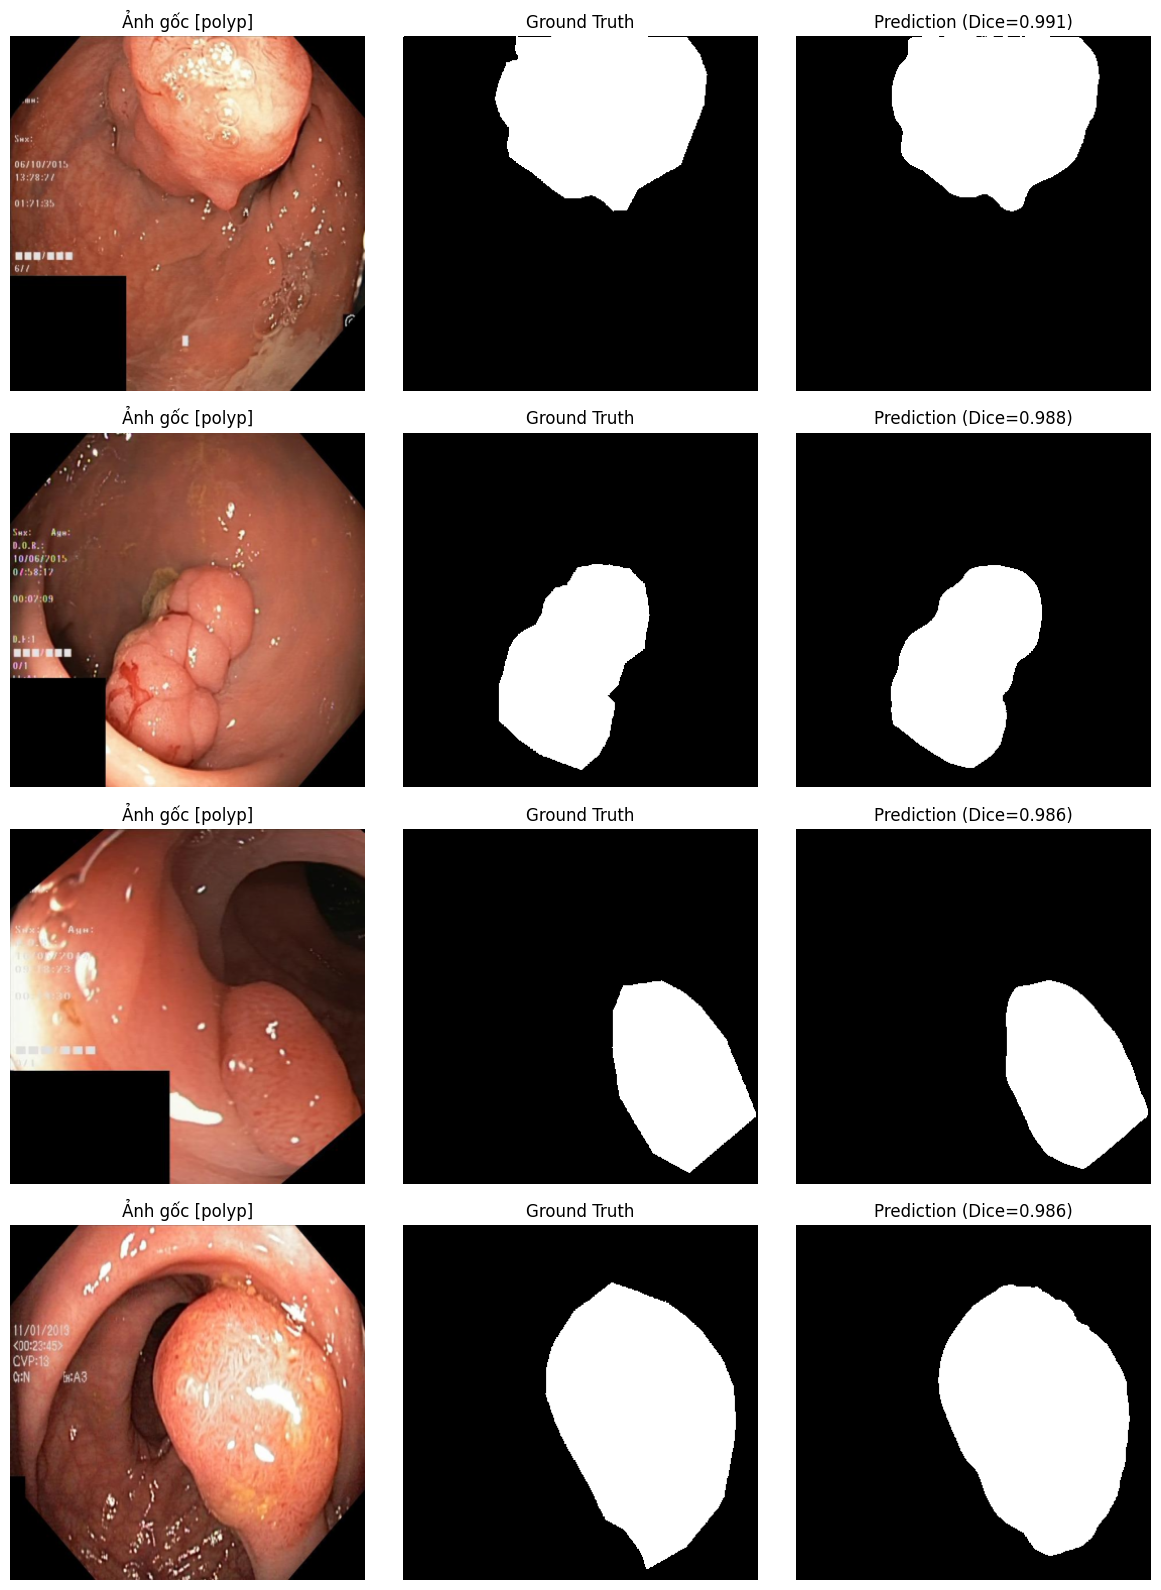

Đã lưu tại: ..\checkpoints\test_best_predictions.png


In [20]:
# Ảnh khoanh ĐÚNG: các ảnh POLYP có Dice cao nhất (model tô trúng khối polyp).
# Chỉ lấy ảnh polyp vì ảnh normal Dice=1.0 nhìn toàn đen, không có gì để khoe.
dice_arr = np.array(all_dice)
labels = [e["label"] for e in splits["test"]]
polyp_idx = np.array([i for i, lb in enumerate(labels) if lb == "polyp"])

best_idx = polyp_idx[np.argsort(dice_arr[polyp_idx])[::-1][:4]]   # 4 ảnh tốt nhất

print("=== ẢNH KHOANH ĐÚNG (Dice cao nhất) ===")
show_cases(model, test_dataset, splits["test"], best_idx, DEVICE, "test_best_predictions.png")
print("Đã lưu tại:", SAVE_DIR / "test_best_predictions.png")

=== ẢNH KHOANH SAI (Dice thấp nhất) ===


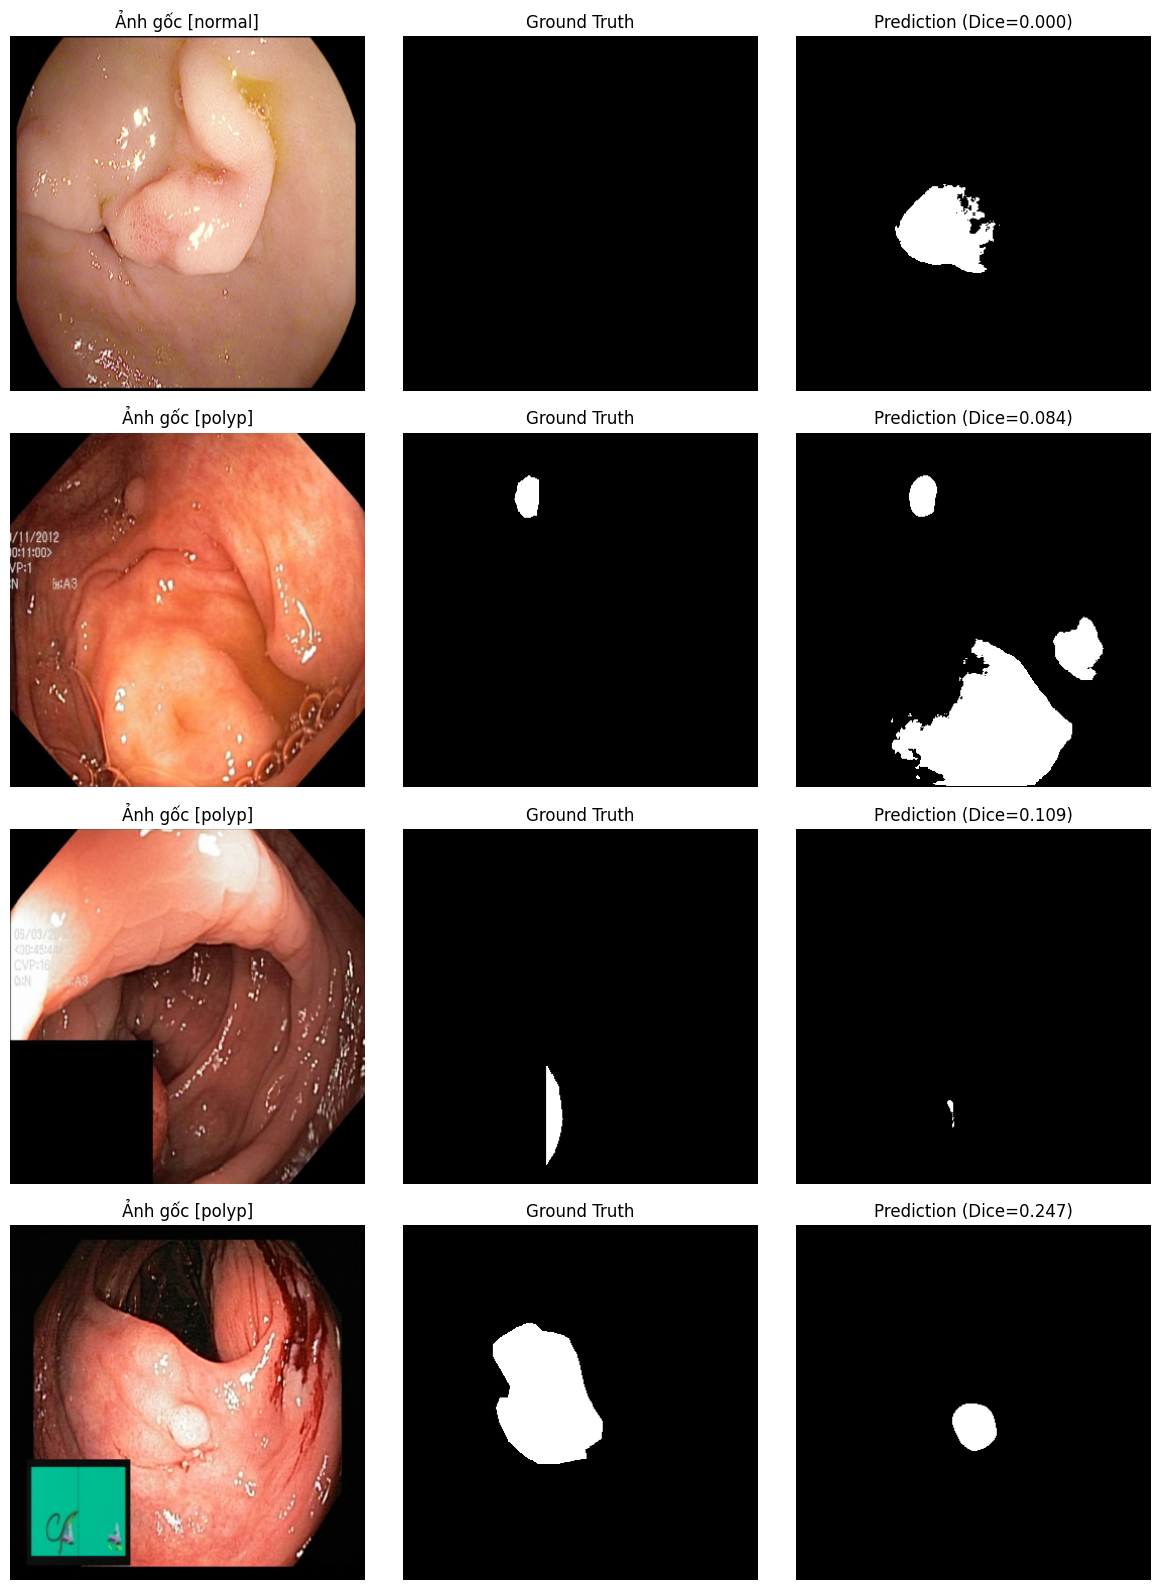

Đã lưu tại: ..\checkpoints\test_worst_predictions.png


In [21]:
# Ảnh khoanh SAI: các ảnh có Dice thấp nhất (bỏ sót polyp hoặc vẽ nhầm trên mô lành).
worst_idx = np.argsort(np.array(all_dice))[:4]   # 4 ảnh tệ nhất

print("=== ẢNH KHOANH SAI (Dice thấp nhất) ===")
show_cases(model, test_dataset, splits["test"], worst_idx, DEVICE, "test_worst_predictions.png")
print("Đã lưu tại:", SAVE_DIR / "test_worst_predictions.png")